# 3b. Bridge: Diffusion, Scores and Flow Matching Are One Framework

**Read this after notebook 3 and before notebook 4.** Notebooks 1–3 predict noise $\epsilon$; notebook 4 predicts a velocity $v$; notebook 7 predicts an energy whose gradient is a score. It is easy to come away thinking these are three different ideas. They are not. This notebook shows, with exact formulas you can check numerically, that they are three views of one object.

We use a 2D Gaussian-mixture "dataset" because for a Gaussian mixture **every quantity a network would try to learn has a closed form**: the noised density, its score, the optimal denoiser, and the optimal velocity field. So there is no training here: we compute the answers a perfect network would converge to, and study them.

What you will see:

1. **One family of noising paths** $x_t = a_t\,x_{\text{data}} + b_t\,\epsilon$ covers DDPM, the VP-SDE (notebook 7), and the straight-line path of flow matching (notebook 4).
2. **Four interchangeable predictions**: noise $\hat\epsilon$, clean data $\hat x$, score $s$, velocity $v$. Knowing any one at $(x_t, t)$ gives you all the others.
3. **Conditional vs. marginal velocity.** Each training pair moves in a straight line, but the field the network learns is an *average*, and its trajectories are **curved**. Why the flow-matching loss never reaches zero.
4. **DDPM, DDIM and flow matching samplers** side by side: stochastic vs. deterministic, and how many steps each needs.
5. **Same map, different clocks.** The DDIM (probability-flow) ODE and the flow-matching ODE send the same noise to (almost exactly) the same sample.
6. **Guidance is score arithmetic.** Classifier-free guidance (notebook 3) adds scores, and why that is *not* the same as sampling $p(x)\,p(y\mid x)^w$.

Prerequisites: 0b (score, Tweedie's formula) and 0c (SDEs, probability-flow ODE).

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)   # exact formulas -> use double precision
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 12

---
## 1. The data: a labelled Gaussian mixture

Four isotropic Gaussian blobs, each with variance $s^2 = 0.3$ per coordinate (the same mixture as 0b). The blobs carry **class labels** so that later we can do conditional generation and guidance: class 0 is the diagonal pair, class 1 the anti-diagonal pair.

$$p_{\text{data}}(x) = \sum_{k=1}^{4} \pi_k\, \mathcal{N}(x;\, \mu_k,\, s^2 I)$$

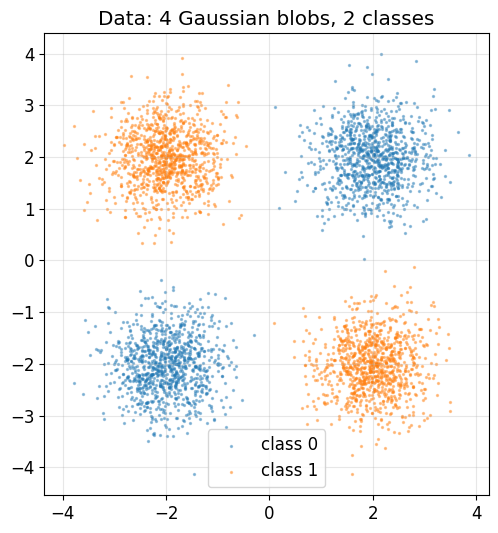

In [2]:
MU = torch.tensor([[2., 2.], [-2., -2.], [-2., 2.], [2., -2.]])
S2 = 0.3                                   # per-coordinate variance of each blob
PI = torch.full((4,), 0.25)
LABEL = torch.tensor([0, 0, 1, 1])         # class of each blob
D = 2

def sample_data(n, y=None, generator=None):
    # Sample from the mixture (optionally only from blobs of class y).
    probs = PI.clone() if y is None else PI * (LABEL == y)
    k = torch.multinomial(probs / probs.sum(), n, replacement=True, generator=generator)
    return MU[k] + np.sqrt(S2) * torch.randn(n, D, generator=generator)

torch.manual_seed(0)
data = sample_data(4000)
plt.figure(figsize=(6, 6))
for y, c in [(0, 'tab:blue'), (1, 'tab:orange')]:
    pts = data[LABEL[torch.cdist(data, MU).argmin(1)] == y]
    plt.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.4, c=c, label=f'class {y}')
plt.legend(); plt.gca().set_aspect('equal'); plt.grid(alpha=0.3)
plt.title('Data: 4 Gaussian blobs, 2 classes')
plt.show()

---
## 2. One family of noising paths

Every method in this repo corrupts data the same way:

$$x_t = a_t\, x_{\text{data}} + b_t\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

Only the **schedule** $(a_t, b_t)$ and the **direction of time** differ:

| Method | Notebook | $a_t$ (signal) | $b_t$ (noise) | Noise at | Data at |
|---|---|---|---|---|---|
| DDPM (discrete) | 1–3 | $\sqrt{\bar\alpha_t}$ | $\sqrt{1-\bar\alpha_t}$ | $t = T$ | $t = 0$ |
| VP-SDE (continuous DDPM) | 7, 0c | $e^{-B(t)/2}$ | $\sqrt{1 - e^{-B(t)}}$ | $t = 1$ | $t = 0$ |
| Flow matching, linear path | 4–6 | $t$ | $1 - t$ | $t = 0$ | $t = 1$ |

⚠️ **Time runs in opposite directions.** In DDPM, large $t$ means *more noise*. In notebook 4's flow matching, large $t$ means *more data* (noise is called $x_0$, data $x_1$). This is the single most common source of confusion when reading papers side by side.

What matters for the shape of $p_t$ is the **signal-to-noise ratio** $\text{SNR} = a_t^2 / b_t^2$. VP paths keep $a_t^2 + b_t^2 = 1$ (variance preserving); the linear path does not: at $t=0.5$, $a_t^2 + b_t^2 = 0.5$.

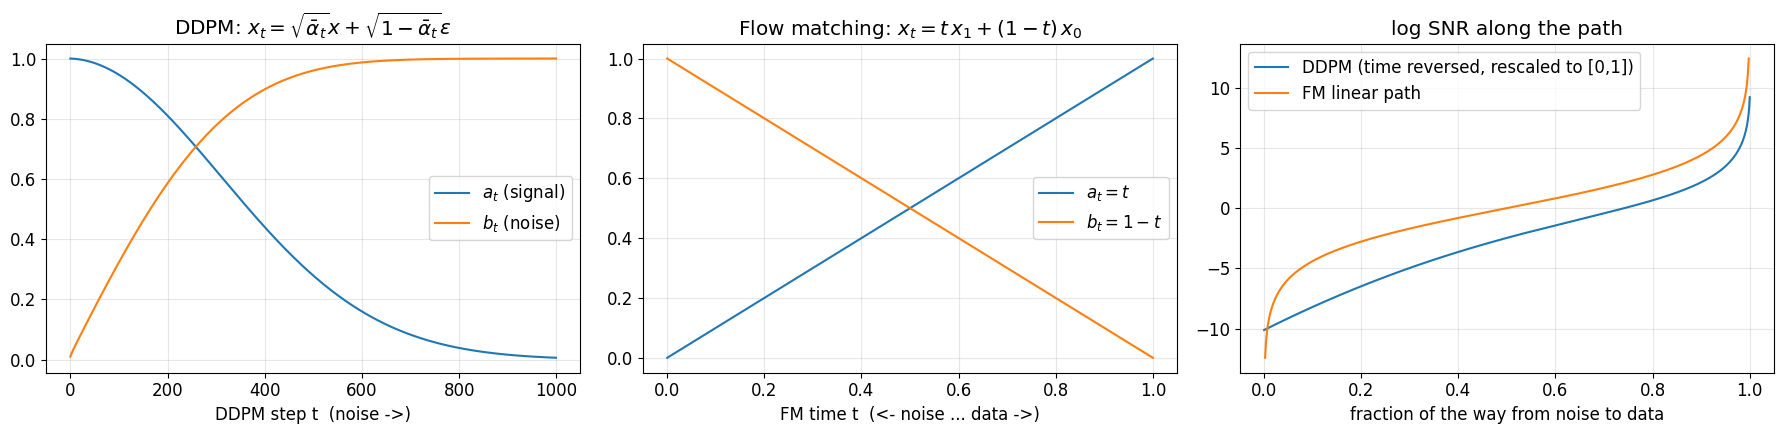

DDPM endpoint: a_T = 0.0064  (signal left at the 'pure noise' end)


In [3]:
# DDPM schedule (T = 1000 is the standard choice; see note in section 2.1)
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alpha_bars = torch.cumprod(1 - betas, 0)
ddpm_a, ddpm_b = alpha_bars.sqrt(), (1 - alpha_bars).sqrt()

t_fm = torch.linspace(0, 1, 500)
fm_a, fm_b = t_fm, 1 - t_fm

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(ddpm_a, label='$a_t$ (signal)'); axes[0].plot(ddpm_b, label='$b_t$ (noise)')
axes[0].set_title('DDPM: $x_t=\\sqrt{\\bar\\alpha_t}x + \\sqrt{1-\\bar\\alpha_t}\\epsilon$'); axes[0].set_xlabel('DDPM step t  (noise ->)')
axes[1].plot(t_fm, fm_a, label='$a_t = t$'); axes[1].plot(t_fm, fm_b, label='$b_t = 1-t$')
axes[1].set_title('Flow matching: $x_t = t\\,x_1 + (1-t)\\,x_0$'); axes[1].set_xlabel('FM time t  (<- noise ... data ->)')
# Compare on a common axis: log-SNR
axes[2].plot(np.linspace(1, 0, T), torch.log(ddpm_a**2 / ddpm_b**2), label='DDPM (time reversed, rescaled to [0,1])')
axes[2].plot(t_fm[1:-1], torch.log(fm_a[1:-1]**2 / fm_b[1:-1]**2), label='FM linear path')
axes[2].set_title('log SNR along the path'); axes[2].set_xlabel('fraction of the way from noise to data')
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"DDPM endpoint: a_T = {ddpm_a[-1]:.4f}  (signal left at the 'pure noise' end)")

### 2.1 A practical note on the schedule length

The linear schedule `linspace(1e-4, 0.02, T)` was designed for $T = 1000$, where $\bar\alpha_T \approx 4\times10^{-5}$, so $x_T$ really is pure noise. Notebooks 1 and 7 reuse the same endpoints with **$T = 200$–$300$**, so each step adds less noise in total. Let's check how much signal is left at the end:

In [4]:
for T_ in [200, 300, 1000]:
    ab = torch.cumprod(1 - torch.linspace(1e-4, 0.02, T_), 0)[-1]
    print(f"T = {T_:4d}:  alpha_bar_T = {ab:.2e}   signal coefficient sqrt(alpha_bar_T) = {ab.sqrt():.3f}")

T =  200:  alpha_bar_T = 1.32e-01   signal coefficient sqrt(alpha_bar_T) = 0.364
T =  300:  alpha_bar_T = 4.81e-02   signal coefficient sqrt(alpha_bar_T) = 0.219
T = 1000:  alpha_bar_T = 4.04e-05   signal coefficient sqrt(alpha_bar_T) = 0.006


With $T = 200$, about a third of the signal amplitude survives at $t = T$, but sampling starts from $x_T \sim \mathcal{N}(0, I)$ as if none did. For the spiral data (which is centred and has a small spread) this mismatch is mild and the notebooks still work. It is still worth knowing about: sampling starts from a distribution slightly different from the one the model was trained on at $t = T$. Either use $T = 1000$ or scale the betas up (e.g. `linspace(1e-4, 0.02 * 1000 / T, T)`) when changing $T$.

---
## 3. Exact answers for a Gaussian mixture

Because $x_t \mid (x_{\text{data}} \text{ in blob } k) \sim \mathcal{N}(a\mu_k,\ (a^2 s^2 + b^2) I)$, the noised marginal is again a Gaussian mixture:

$$p_t(x) = \sum_k \pi_k\, \mathcal{N}\big(x;\ a\mu_k,\ \sigma_k^2 I\big), \qquad \sigma_k^2 = a^2 s^2 + b^2 \;(\text{the same for every blob here, since all blobs share } s^2)$$

From this we get closed forms for:

- the **responsibilities** $w_k(x) = P(\text{blob } k \mid x_t = x)$, a softmax over blobs;
- the **score** $s(x) = \nabla_x \log p_t(x) = \sum_k w_k(x)\,\big(-(x - a\mu_k)/\sigma_k^2\big)$;
- the **optimal denoiser** $\hat x(x) = \mathbb{E}[x_{\text{data}} \mid x_t = x] = \sum_k w_k(x)\big(\mu_k + \tfrac{a s^2}{\sigma_k^2}(x - a\mu_k)\big)$ (Gaussian conditioning inside each blob, see 0b §1.4).

`y` restricts everything to the blobs of one class, giving the class-conditional versions $p_t(x \mid y)$.

In [5]:
def _blob_terms(x, a, b, y=None):
    var = a**2 * S2 + b**2                                  # sigma_k^2 (same for all blobs)
    d2 = ((x[:, None, :] - a * MU[None]) ** 2).sum(-1)      # (N, K)
    logits = torch.log(PI) - 0.5 * d2 / var - 0.5 * D * np.log(2 * np.pi * var)
    if y is not None:
        logits = logits.masked_fill(LABEL[None] != y, -torch.inf) - torch.log((PI * (LABEL == y)).sum())
    return logits, var

def log_pt(x, a, b, y=None):
    logits, _ = _blob_terms(x, a, b, y)
    return torch.logsumexp(logits, 1)

def score(x, a, b, y=None):
    logits, var = _blob_terms(x, a, b, y)
    w = torch.softmax(logits, 1)                            # responsibilities w_k(x)
    per_blob = -(x[:, None, :] - a * MU[None]) / var        # score of each blob
    return (w[..., None] * per_blob).sum(1)

def x_hat(x, a, b, y=None):
    # E[x_data | x_t = x]  -- the optimal denoiser.
    logits, var = _blob_terms(x, a, b, y)
    w = torch.softmax(logits, 1)
    per_blob = MU[None] + (a * S2 / var) * (x[:, None, :] - a * MU[None])
    return (w[..., None] * per_blob).sum(1)

# Sanity check 1: the closed-form score equals autograd of log p_t
x = torch.randn(5, D) * 2
a, b = 0.6, 0.8
xr = x.clone().requires_grad_(True)
autograd_score = torch.autograd.grad(log_pt(xr, a, b).sum(), xr)[0]
print("max |closed form - autograd| =", (score(x, a, b) - autograd_score).abs().max().item())

# Sanity check 2: the closed-form denoiser equals a Monte Carlo estimate of E[x_data | x_t]
torch.manual_seed(1)
x_data = sample_data(4_000_000)
x_t = a * x_data + b * torch.randn_like(x_data)
x_query = torch.tensor([[1.0, 0.5]])
near = (x_t - x_query).norm(dim=1) < 0.03                   # samples whose x_t landed near x_query
mc, se = x_data[near].mean(0), x_data[near].std(0) / near.sum().sqrt()
print(f"E[x_data | x_t ~ {x_query.tolist()[0]}]:")
print(f"  Monte Carlo  {mc.numpy().round(3)}  +/- {se.numpy().round(3)} (std. error, {near.sum().item()} samples)")
print(f"  closed form  {x_hat(x_query, a, b)[0].numpy().round(3)}")
print("  (agreement to within ~2 standard errors is all Monte Carlo can show; the finite bin adds a little bias too)")

max |closed form - autograd| = 2.220446049250313e-15


E[x_data | x_t ~ [1.0, 0.5]]:
  Monte Carlo  [1.736 1.252]  +/- [0.038 0.059] (std. error, 552 samples)
  closed form  [1.819 1.259]
  (agreement to within ~2 standard errors is all Monte Carlo can show; the finite bin adds a little bias too)


---
## 4. Four predictions, one piece of information

A network in this repo is asked to predict one of the following at $(x_t, t)$. Each is the **conditional expectation** of something given $x_t$, because MSE regression learns conditional means (0b §6):

| Network predicts | Optimal value | Used in |
|---|---|---|
| noise $\hat\epsilon$ | $\mathbb{E}[\epsilon \mid x_t]$ | notebooks 1–3 (DDPM) |
| clean data $\hat x$ | $\mathbb{E}[x_{\text{data}} \mid x_t]$ | many modern models; DDIM's intermediate |
| score $s$ | $\nabla_x \log p_t(x_t)$ | notebook 7 (as $-\nabla_x E$) |
| velocity $v$ | $\mathbb{E}[\dot a_t\,x_{\text{data}} + \dot b_t\,\epsilon \mid x_t]$ | notebooks 4–6 |

Since $x_t = a_t \hat{x} + b_t \hat\epsilon$ holds *exactly* for the conditional means (take $\mathbb{E}[\cdot \mid x_t]$ of both sides of the path equation), and Tweedie's formula gives the score, all four are linked by fixed linear maps:

$$\hat\epsilon = \frac{x_t - a_t \hat x}{b_t}, \qquad s = -\frac{\hat\epsilon}{b_t} = \frac{a_t\hat x - x_t}{b_t^2}, \qquad v = \dot a_t\, \hat x + \dot b_t\, \hat\epsilon$$

For notebook 4's linear path ($a_t = t$, $b_t = 1-t$, so $\dot a = 1, \dot b = -1$):

$$v = \hat x - \hat\epsilon = \frac{x_t - \hat\epsilon}{t} = \frac{x_t + (1-t)\, s}{t}$$

So "predict noise" vs "predict velocity" is a choice of **output parameterization and loss weighting**, not a different model of the data. (The choice still matters in practice: each makes the regression target better or worse conditioned at different noise levels.)

In [6]:
# Verify the conversions numerically on the linear (flow matching) path
torch.manual_seed(0)
t = 0.35
a, b = t, 1 - t
xd = sample_data(4_000_000)
eps = torch.randn_like(xd)
xt = a * xd + b * eps

xh = x_hat(xt, a, b)
eh = (xt - a * xh) / b                                  # noise prediction from denoiser
s_from_eps = -eh / b
v_from_x_eps = xh - eh                                  # v = x_hat - eps_hat
v_from_score = (xt + (1 - t) * score(xt, a, b)) / t

print("score:  |-eps_hat/b - exact score|_max  =", (s_from_eps - score(xt, a, b)).abs().max().item())
print("vel.:   |x_hat - eps_hat - (x+(1-t)s)/t|_max =", (v_from_x_eps - v_from_score).abs().max().item())

# The optimal velocity really is E[x_data - eps | x_t]: compare with the training target in a small bin
x_query = torch.tensor([[0.8, 0.2]])
near = (xt - x_query).norm(dim=1) < 0.03
tg = (xd - eps)[near]
print(f"\nAt x_t ~ {x_query.tolist()[0]}, t={t}  ({near.sum().item()} training samples in the bin):")
print("  mean of training targets (x_data - eps) in bin:", tg.mean(0).numpy().round(3), "+/-", (tg.std(0) / near.sum().sqrt()).numpy().round(3))
print("  closed-form marginal velocity v(x_t):         ", (x_hat(x_query, a, b) - (x_query - a * x_hat(x_query, a, b)) / b)[0].numpy().round(3))
print("  spread (std) of the targets in that bin:      ", (xd - eps)[near].std(0).numpy().round(3), " <- irreducible")

score:  |-eps_hat/b - exact score|_max  = 4.440892098500626e-15
vel.:   |x_hat - eps_hat - (x+(1-t)s)/t|_max = 8.659739592076221e-15

At x_t ~ [0.8, 0.2], t=0.35  (1267 training samples in the bin):
  mean of training targets (x_data - eps) in bin: [1.476 0.496] +/- [0.046 0.079]
  closed-form marginal velocity v(x_t):          [1.427 0.6  ]
  spread (std) of the targets in that bin:       [1.655 2.815]  <- irreducible


---
## 5. Conditional vs. marginal velocity: why flow-matching paths are *not* straight

It is tempting to say "the velocity is constant along the path, so it is easy to learn". That is true for the **conditional** velocity, the velocity of one training pair $(x_0, x_1)$: $u = x_1 - x_0$.

But the network sees only $x_t$, not which pair produced it. Many pairs pass through the same point $x_t$ heading in different directions, so the best the network can do is predict their **average**:

$$v^*(x, t) = \mathbb{E}[\,x_1 - x_0 \mid x_t = x\,]$$

This **marginal velocity field** is what notebook 4's network actually learns. Its trajectories:

- **do not cross** (ODE solutions are unique), whereas the straight training lines cross all the time;
- are **curved**, because $v^*$ changes along the way as the posterior over "which data point am I heading to" sharpens;
- still transport $\mathcal{N}(0, I)$ exactly to $p_{\text{data}}$. That is the flow-matching theorem (Lipman et al., 2023).

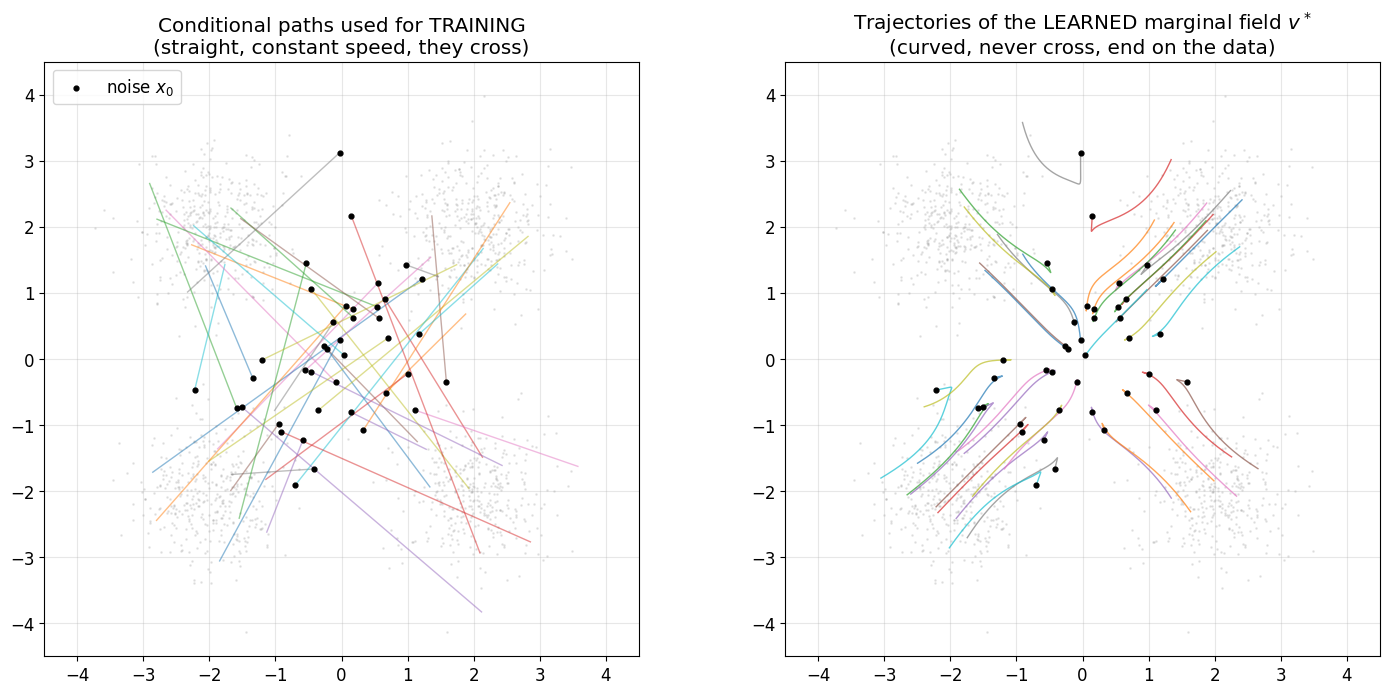

In [7]:
def fm_velocity(x, t, y=None):
    # Exact marginal velocity for the linear path x_t = t*x_data + (1-t)*eps.
    a, b = t, 1 - t
    xh = x_hat(x, a, b, y)
    eh = (x - a * xh) / b
    return xh - eh

def integrate_fm(x0, steps, y=None, w=None, keep_path=False):
    # Euler integration of dx/dt = v(x,t) from t=0 (noise) to t=1 (data).
    # w: optional classifier-free guidance scale (section 8).
    x, dt, path = x0.clone(), 1.0 / steps, [x0.clone()]
    for i in range(steps):
        t = i * dt
        if w is None:
            v = fm_velocity(x, t, y)
        else:
            v_u, v_c = fm_velocity(x, t), fm_velocity(x, t, y)
            v = v_u + w * (v_c - v_u)
        x = x + dt * v
        if keep_path: path.append(x.clone())
    return (x, torch.stack(path)) if keep_path else x

torch.manual_seed(3)
n_show = 40
noise = torch.randn(n_show, D)
paired_data = sample_data(n_show)                       # random (independent) pairing, as in training
_, ode_path = integrate_fm(noise, 200, keep_path=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for i in range(n_show):
    axes[0].plot([noise[i, 0], paired_data[i, 0]], [noise[i, 1], paired_data[i, 1]], '-', alpha=0.5, lw=1)
    axes[1].plot(ode_path[:, i, 0], ode_path[:, i, 1], '-', alpha=0.7, lw=1)
for ax in axes:
    ax.scatter(noise[:, 0], noise[:, 1], c='k', s=12, zorder=5, label='noise $x_0$')
    ax.scatter(*data[:1500].T, s=1, alpha=0.15, c='gray')
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect('equal'); ax.grid(alpha=0.3)
axes[0].set_title('Conditional paths used for TRAINING\n(straight, constant speed, they cross)')
axes[1].set_title('Trajectories of the LEARNED marginal field $v^*$\n(curved, never cross, end on the data)')
axes[0].legend(loc='upper left')
plt.tight_layout(); plt.show()

### 5.1 The flow-matching loss has a floor, and that's fine

Training minimises the **conditional** loss $\mathcal{L}_{\text{CFM}}(v) = \mathbb{E}\,\|v(x_t,t) - (x_1 - x_0)\|^2$, because it only needs samples. What we actually want is the **marginal** loss $\mathcal{L}_{\text{FM}}(v) = \mathbb{E}\,\|v(x_t,t) - v^*(x_t,t)\|^2$, which we can't compute. The key identity (expand the square, use $v^* = \mathbb{E}[x_1 - x_0 \mid x_t]$):

$$\mathcal{L}_{\text{CFM}}(v) = \mathcal{L}_{\text{FM}}(v) + \underbrace{\mathbb{E}\,\big\|\,(x_1 - x_0) - v^*(x_t, t)\big\|^2}_{\text{does not depend on } v}$$

So the two losses have **the same minimiser and the same gradients**, but $\mathcal{L}_{\text{CFM}}$ never reaches zero: its floor is the average variance of the targets at each point. The same argument applies to DDPM's $\epsilon$-loss (*denoising score matching*, 0b §6). A loss curve that plateaus well above zero is expected, not a sign that training failed.

In [8]:
torch.manual_seed(0)
n = 200000
x1 = sample_data(n); x0 = torch.randn(n, D); t = torch.rand(n, 1) * 0.98 + 0.01
xt = t * x1 + (1 - t) * x0
target = x1 - x0

# exact marginal velocity at every sample (same formulas as x_hat, vectorised over per-sample t)
a_, b_ = t, 1 - t
var = a_**2 * S2 + b_**2
d2 = ((xt[:, None, :] - a_[:, :, None] * MU[None]) ** 2).sum(-1)
wts = torch.softmax(-0.5 * d2 / var, 1)
xh = (wts[..., None] * (MU[None] + (a_ * S2 / var)[:, :, None] * (xt[:, None, :] - a_[:, :, None] * MU[None]))).sum(1)
v_star = xh - (xt - a_ * xh) / b_

candidates = {
    'v = v* (optimal)': v_star,
    'v = v* + 0.3': v_star + 0.3,
    'v = 0': torch.zeros_like(v_star),
    'v = -x_t (a guess)': -xt,
}
print(f"{'candidate field':30s} {'L_CFM':>8s} {'L_FM':>8s} {'difference':>11s}")
for name, v in candidates.items():
    l_cfm = ((v - target) ** 2).sum(1).mean().item()
    l_fm = ((v - v_star) ** 2).sum(1).mean().item()
    print(f"{name:30s} {l_cfm:8.3f} {l_fm:8.3f} {l_cfm - l_fm:11.3f}")
print("\nThe difference is the same constant for every candidate (up to Monte Carlo noise in the 3rd decimal):")
print("it is the irreducible floor of the training loss.")

candidate field                   L_CFM     L_FM  difference
v = v* (optimal)                  5.671    0.000       5.671
v = v* + 0.3                      5.849    0.180       5.669
v = 0                            10.599    4.932       5.667
v = -x_t (a guess)               20.717   15.048       5.668

The difference is the same constant for every candidate (up to Monte Carlo noise in the 3rd decimal):
it is the irreducible floor of the training loss.


---
## 6. Three samplers on the same problem

Given perfect predictions, how do the samplers compare? We use the exact $\hat\epsilon$ / $v^*$ so that the only error is **discretisation**, i.e. the effect of the number of steps.

- **DDPM ancestral** (notebooks 1–3): stochastic, injects fresh noise each step. A discretisation of the reverse-time SDE (0c §4.7).
- **DDIM** (Song et al., 2021): deterministic. It is the DDPM model run through the **probability-flow ODE**; it reuses the same trained $\epsilon$-network, unchanged. One step: predict $\hat x$, then re-noise it *deterministically* with the predicted noise:
  $$x_{t'} = \sqrt{\bar\alpha_{t'}}\,\hat x + \sqrt{1 - \bar\alpha_{t'}}\;\hat\epsilon$$
- **Flow matching Euler** (notebook 4): deterministic, $x \leftarrow x + v\,\Delta t$.

Both DDPM and DDIM can skip timesteps (use a sub-sequence of the 1000). The generalised update below interpolates between them with $\eta$ ($\eta=0$: DDIM; $\eta=1$: DDPM-like ancestral sampling on the sub-sequence).

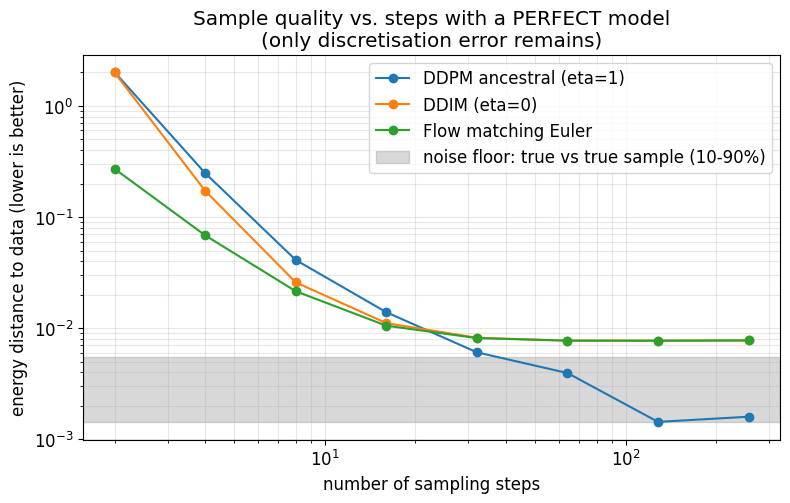

In [9]:
def eps_hat_ddpm(x, t_idx, y=None):
    a, b = ddpm_a[t_idx].item(), ddpm_b[t_idx].item()
    return (x - a * x_hat(x, a, b, y)) / b

def sample_ddim(x, steps, eta=0.0, y=None, generator=None):
    # Generalised DDIM sampler on an evenly spaced sub-sequence of the T DDPM steps.
    seq = torch.linspace(T - 1, 0, steps).round().long()
    for i, t_idx in enumerate(seq):
        ab = alpha_bars[t_idx]
        ab_prev = alpha_bars[seq[i + 1]] if i + 1 < steps else torch.tensor(1.0)
        e = eps_hat_ddpm(x, t_idx, y)
        x0_pred = (x - (1 - ab).sqrt() * e) / ab.sqrt()
        sigma = eta * ((1 - ab_prev) / (1 - ab) * (1 - ab / ab_prev)).sqrt()
        noise = torch.randn(x.shape, generator=generator) if eta > 0 else 0.0
        x = ab_prev.sqrt() * x0_pred + (1 - ab_prev - sigma**2).clamp(min=0).sqrt() * e + sigma * noise
    return x

def energy_distance(X, Y):
    # Energy distance between two samples: 0 iff same distribution (larger = worse).
    return (2 * torch.cdist(X, Y).mean() - torch.cdist(X, X).mean() - torch.cdist(Y, Y).mean()).item()

torch.manual_seed(0)
ref = sample_data(2000)
start = torch.randn(2000, D)
step_counts = [2, 4, 8, 16, 32, 64, 128, 256]
results = {'DDPM ancestral (eta=1)': [], 'DDIM (eta=0)': [], 'Flow matching Euler': []}
for n_steps in step_counts:
    g = torch.Generator().manual_seed(1)
    results['DDPM ancestral (eta=1)'].append(energy_distance(sample_ddim(start, n_steps, eta=1.0, generator=g), ref))
    results['DDIM (eta=0)'].append(energy_distance(sample_ddim(start, n_steps, eta=0.0), ref))
    results['Flow matching Euler'].append(energy_distance(integrate_fm(start, n_steps), ref))
# Monte Carlo floor: energy distance between independent 2000-point samples of the TRUE data
floors = torch.tensor([energy_distance(sample_data(2000), sample_data(2000)) for _ in range(20)])

plt.figure(figsize=(9, 5))
for name, vals in results.items():
    plt.loglog(step_counts, vals, 'o-', label=name)
plt.axhspan(floors.quantile(0.1).item(), floors.quantile(0.9).item(), color='gray', alpha=0.3,
            label='noise floor: true vs true sample (10-90%)')
plt.xlabel('number of sampling steps'); plt.ylabel('energy distance to data (lower is better)')
plt.title('Sample quality vs. steps with a PERFECT model\n(only discretisation error remains)')
plt.legend(); plt.grid(alpha=0.3, which='both'); plt.show()

In [10]:
# Is the small gap between the deterministic samplers and the grey band at many steps a real bias?
# Check with many more samples: an exact ODE map should reproduce blob frequencies and within-blob variance.
torch.manual_seed(5)
out = integrate_fm(torch.randn(40000, D), 512)
truth = sample_data(40000)
for name, s in [('FM ODE, 512 steps', out), ('true data', truth)]:
    k = torch.cdist(s, MU).argmin(1)
    print(f"{name:18s} blob frequencies {(torch.bincount(k, minlength=4) / len(k)).numpy().round(3)}"
          f"   within-blob variance {(s - MU[k]).var(0).numpy().round(3)}  (target {S2})")
print("-> no detectable bias: the gap at 2000 samples is Monte Carlo noise of a single draw.")

FM ODE, 512 steps  blob frequencies [0.251 0.247 0.252 0.249]   within-blob variance [0.302 0.304]  (target 0.3)
true data          blob frequencies [0.247 0.248 0.252 0.254]   within-blob variance [0.298 0.302]  (target 0.3)
-> no detectable bias: the gap at 2000 samples is Monte Carlo noise of a single draw.


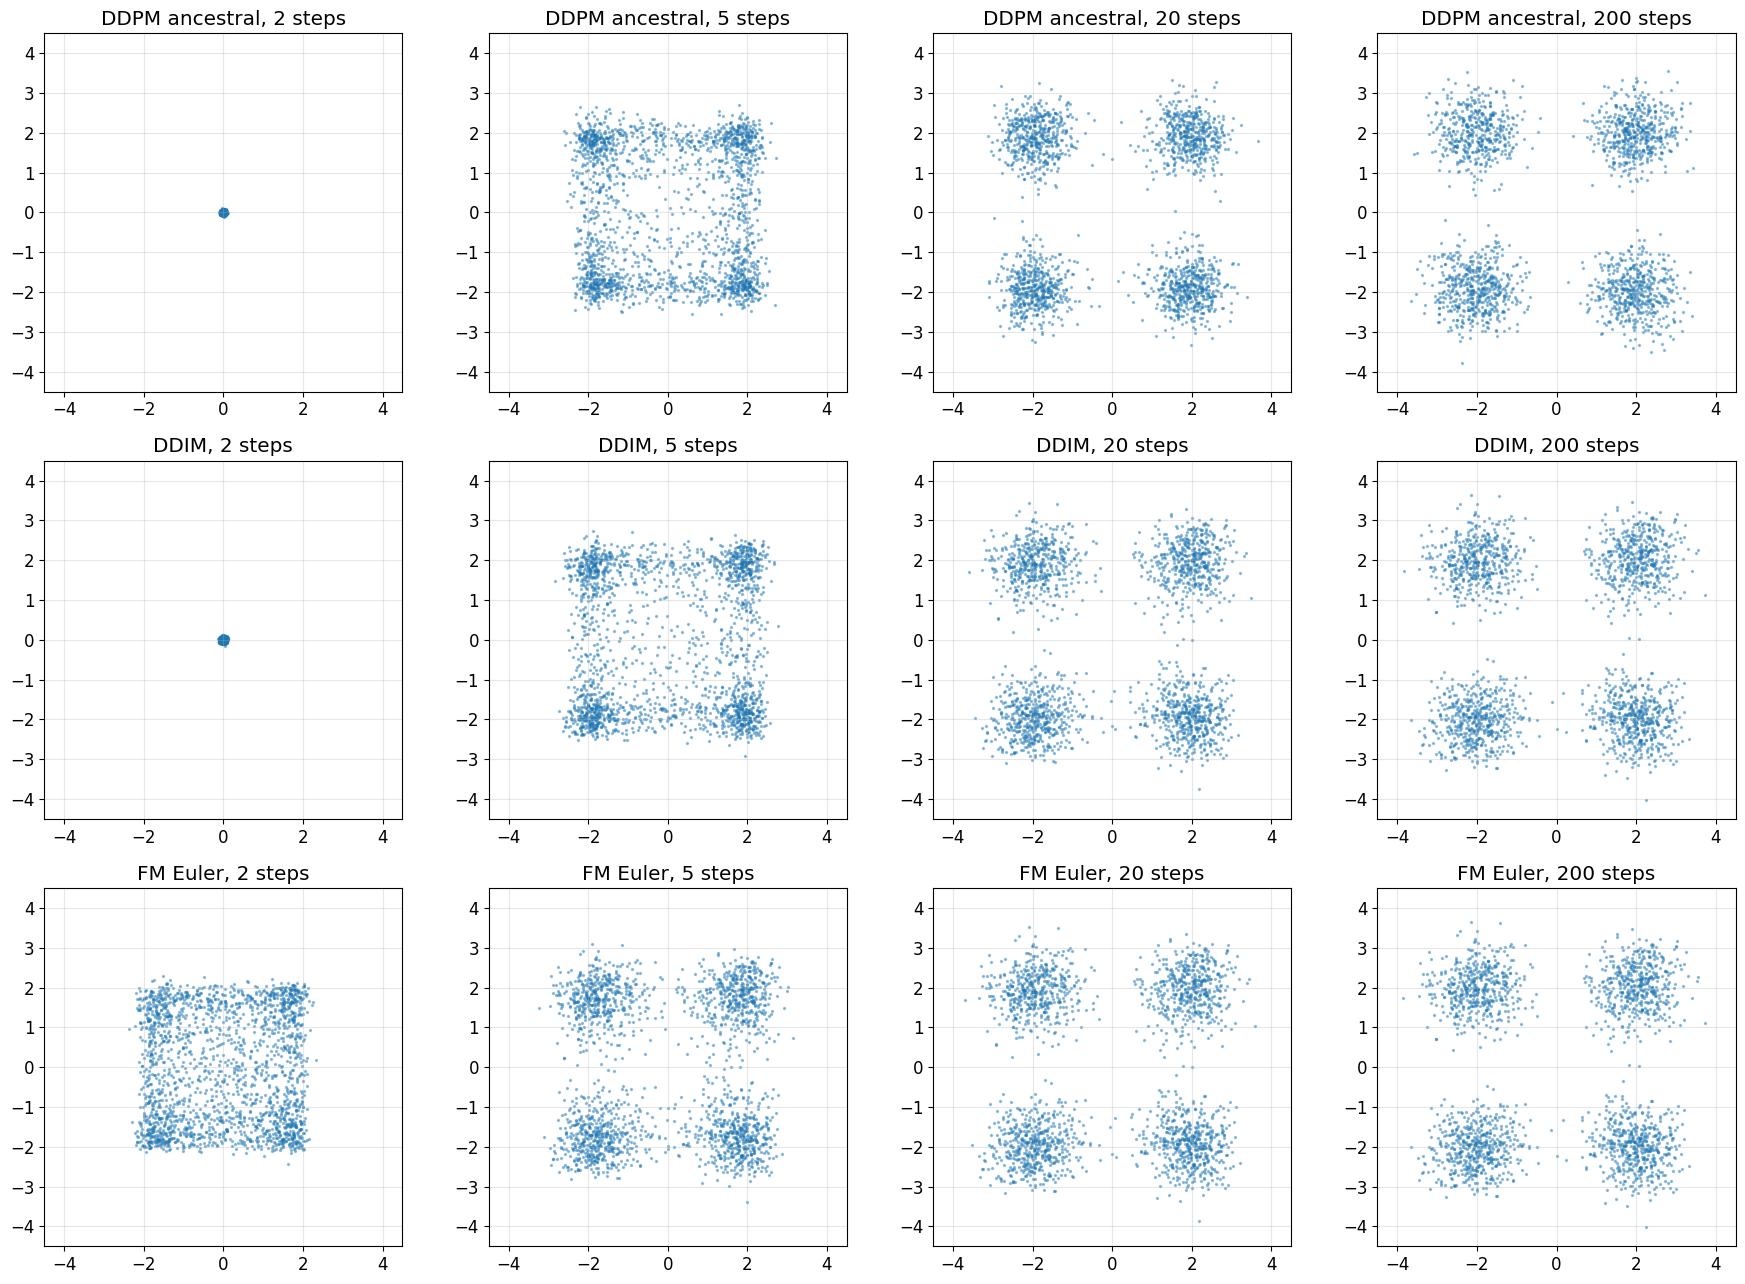

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for row, (name, fn) in enumerate([
        ('DDPM ancestral', lambda n: sample_ddim(start, n, eta=1.0, generator=torch.Generator().manual_seed(1))),
        ('DDIM', lambda n: sample_ddim(start, n, eta=0.0)),
        ('FM Euler', lambda n: integrate_fm(start, n))]):
    for col, n_steps in enumerate([2, 5, 20, 200]):
        s = fn(n_steps)
        ax = axes[row, col]
        ax.scatter(*s.T, s=2, alpha=0.4)
        ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect('equal'); ax.grid(alpha=0.3)
        ax.set_title(f'{name}, {n_steps} steps')
plt.tight_layout(); plt.show()

**What to take away:**

- Below roughly $10^{-2}$ the curves are inside the grey band: differences there are just Monte Carlo noise from using 2000-point samples, not sampler bias.
- In the **few-step** regime the deterministic samplers do better. Ancestral DDPM injects fresh noise every step, which costs accuracy when steps are large. That is why DDIM made diffusion sampling practical and why flow matching is usually run as an ODE. With **many** steps all three converge. The injected noise even helps a little in practice, because it corrects errors that earlier steps accumulated.
- Few-step deterministic samplers fail in a characteristic way: points stop **between** the modes or shrink toward the mean. With 1–2 steps Euler essentially jumps along the initial velocity, which points at the *average* of the data.
- How DDIM compares with FM Euler depends on the data and the schedule. The linear path is not straight for multimodal data (section 5). Rectified flow / reflow and minibatch optimal-transport couplings (see THEORY.md) are techniques that *make* the paths straighter, so that few-step sampling works better.
- A real network adds its own **approximation error** on top. In notebook 4 the 3-step MNIST samples look decent partly because MNIST digits are forgiving; don't read that as a general "flow matching needs 3 steps" rule.

---
## 7. Same map, different clocks

Here is a striking consequence of section 4. Take one noise vector $\epsilon$ and send it through

- the **DDIM ODE** (DDPM schedule, from $t = T$ down to $0$), and
- the **flow-matching ODE** (linear path, from $t = 0$ up to $1$).

These are probability-flow ODEs of two Gaussian paths. A Gaussian path $x_t = a_t x + b_t \epsilon$ is fully described, up to an overall rescaling of $x_t$, by its SNR $a_t/b_t$, and any two such paths visit the same SNR values in the same order. Change variables $\bar x = x_t / a_t$ and the two ODEs become **the same ODE**, just run on different clocks. So with enough steps they map each noise vector to **the same data point**.

median distance  DDIM(eps) vs FM(eps)      : 0.0017
median distance  DDIM(eps) vs random sample : 4.1485


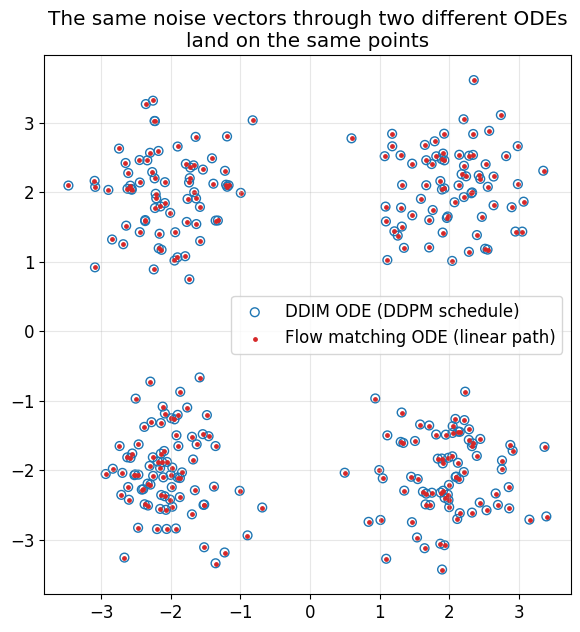

In [12]:
torch.manual_seed(7)
eps0 = torch.randn(1000, D)
out_ddim = sample_ddim(eps0, 1000, eta=0.0)
out_fm = integrate_fm(eps0, 4000)
out_other = sample_data(1000)          # unrelated samples, for scale

d_same = (out_ddim - out_fm).norm(dim=1)
print(f"median distance  DDIM(eps) vs FM(eps)      : {d_same.median():.4f}")
print(f"median distance  DDIM(eps) vs random sample : {(out_ddim - out_other).norm(dim=1).median():.4f}")

plt.figure(figsize=(7, 7))
plt.scatter(*out_ddim[:300].T, s=40, facecolors='none', edgecolors='tab:blue', label='DDIM ODE (DDPM schedule)')
plt.scatter(*out_fm[:300].T, s=6, c='tab:red', label='Flow matching ODE (linear path)')
plt.legend(); plt.gca().set_aspect('equal'); plt.grid(alpha=0.3)
plt.title('The same noise vectors through two different ODEs\nland on the same points')
plt.show()

The small residual difference comes from discretisation and from DDPM's endpoint $\bar\alpha_T \approx 4\times10^{-5}$ not being exactly zero.

**Why this matters:** training with the $\epsilon$-loss (DDPM) or the velocity loss (flow matching) gives networks that, when perfect, encode the *same* deterministic noise→data map. The practical differences between the two families come from (i) how the loss weights different noise levels, (ii) which target is easier for a network to regress, and (iii) the time-discretisation that the sampler uses. They do not come from a different underlying generative process.

---
## 8. Guidance is score arithmetic

Bayes' rule, $p(x \mid y) \propto p(x)\, p(y \mid x)$, becomes **addition** after taking $\nabla_x \log$ (the normaliser $p(y)$ does not depend on $x$):

$$\nabla_x \log p_t(x \mid y) = \nabla_x \log p_t(x) + \nabla_x \log p_t(y \mid x)$$

**Classifier guidance** (Dhariwal & Nichol, 2021) trains a classifier on noisy inputs and adds $w\,\nabla_x \log p_t(y \mid x)$ to the unconditional score. **Classifier-free guidance** (notebook 3) obtains the classifier gradient for free as the difference of two predictions of one network:

$$\nabla_x \log p_t(y \mid x) = \nabla_x \log p_t(x \mid y) - \nabla_x \log p_t(x) \quad\Longrightarrow\quad s_w = s_{\text{uncond}} + w\,(s_{\text{cond}} - s_{\text{uncond}})$$

Because $\hat\epsilon$, $\hat x$ and $v$ are affine in the score at fixed $(x_t, t)$, the same formula works verbatim on noise predictions (notebook 3) and on velocities. Below we apply it to our exact class-conditional and unconditional velocities.

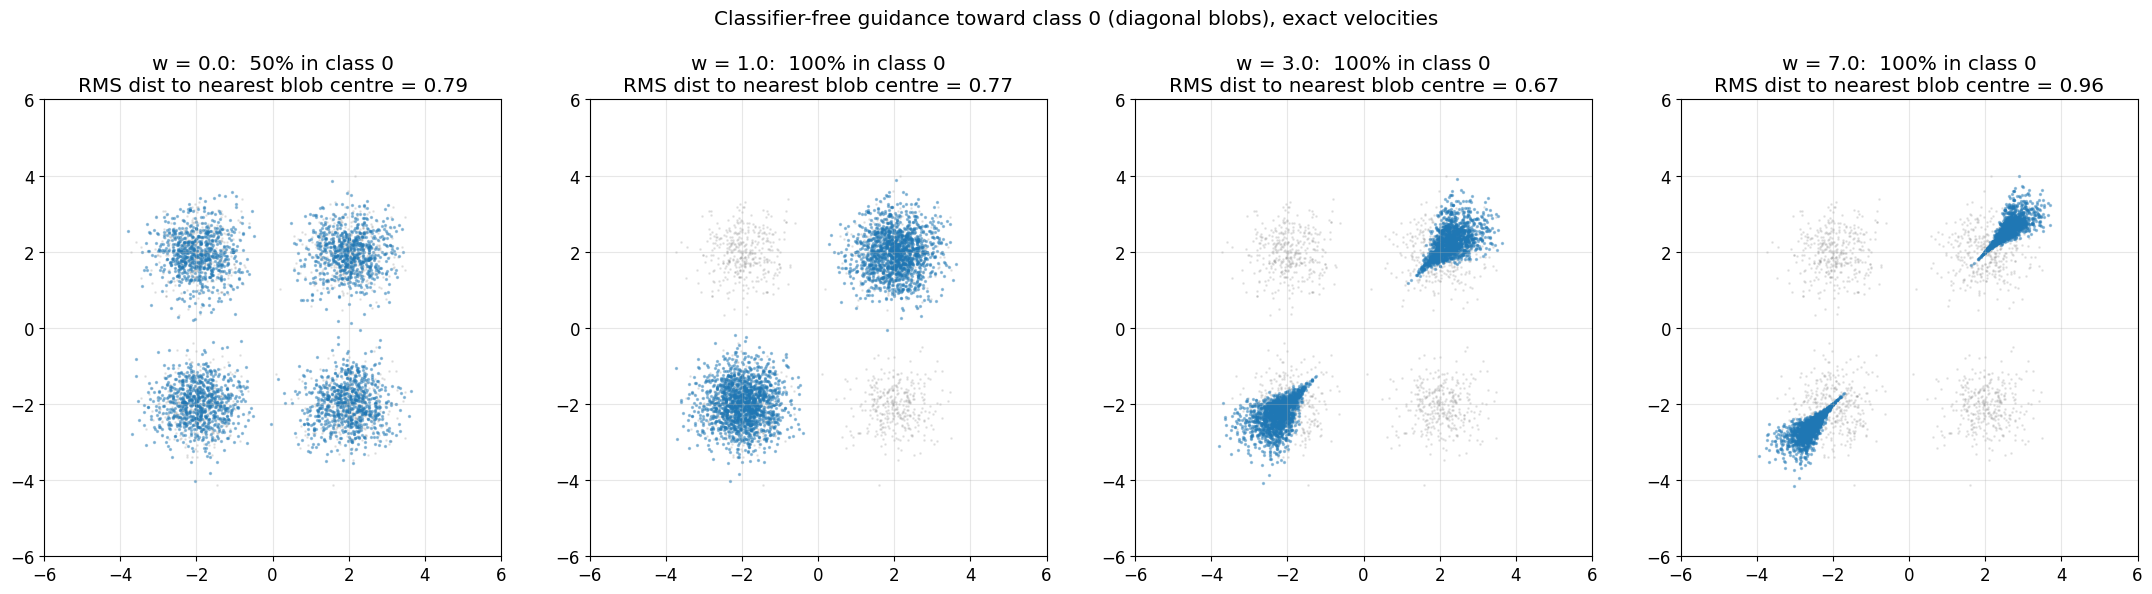

True blob RMS radius: sqrt(2*s^2) = 0.77


In [13]:
torch.manual_seed(0)
start = torch.randn(3000, D)
ws = [0.0, 1.0, 3.0, 7.0]
fig, axes = plt.subplots(1, len(ws), figsize=(22, 5.5))
for ax, w in zip(axes, ws):
    s = integrate_fm(start, 200, y=0, w=w)
    ax.scatter(*data[:1500].T, s=1, c='gray', alpha=0.15)
    ax.scatter(*s.T, s=2, alpha=0.4, c='tab:blue')
    in_class = (LABEL[torch.cdist(s, MU).argmin(1)] == 0).float().mean()
    spread = (s - MU[torch.cdist(s, MU).argmin(1)]).pow(2).sum(1).mean().sqrt()
    ax.set_title(f'w = {w}:  {in_class:.0%} in class 0\nRMS dist to nearest blob centre = {spread:.2f}')
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect('equal'); ax.grid(alpha=0.3)
plt.suptitle('Classifier-free guidance toward class 0 (diagonal blobs), exact velocities', y=1.03)
plt.tight_layout(); plt.show()
print(f"True blob RMS radius: sqrt(2*s^2) = {np.sqrt(2 * S2):.2f}")

Reading the panels:

- $w = 0$ is unconditional (all four blobs); $w = 1$ is exact conditional sampling (only class 0, correct spread).
- $w > 1$ does more than "follow the label harder". The samples are **pushed away from the other class** and the blobs get **distorted**: their spread and shape no longer match the data.

### 8.1 CFG does not sample $p(x)\,p(y\mid x)^w$

A natural guess is that guidance samples the "sharpened" distribution $\tilde p_w(x) \propto p(x)\,p(y \mid x)^w$ of clean data. It doesn't. Guidance tilts **every noisy marginal** $p_t$, and tilting doesn't commute with adding noise. At high noise the classifier $p_t(y \mid x)$ is soft and its gradient is large over a wide region, so early steps get pushed hard. Here the blobs are well separated, so for clean data $p(y=0 \mid x) \approx 1$ on class-0 blobs and the *true* tilted distribution is almost identical to $p(x \mid y=0)$. CFG at $w = 7$ is clearly not:

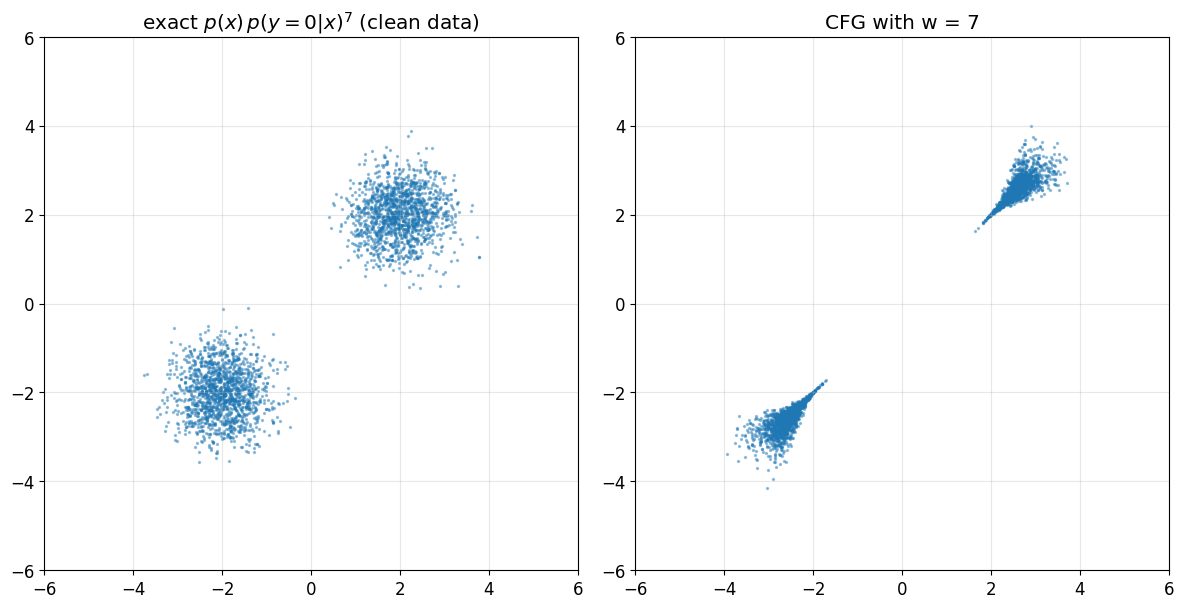

energy distance to p(x|y=0):  tilted target = 0.001   CFG = 0.342


In [14]:
# Exact samples from the tilted target p(x) p(y|x)^w at t=0, by importance resampling
def tilted_samples(w, n=3000):
    cand = sample_data(200000)
    log_p_y_given_x = log_pt(cand, 1.0, 0.0 + 1e-12, y=0) + np.log(0.5) - log_pt(cand, 1.0, 1e-12)
    idx = torch.multinomial(torch.softmax(w * log_p_y_given_x, 0), n, replacement=True)
    return cand[idx]

torch.manual_seed(0)
w = 7.0
cfg = integrate_fm(torch.randn(3000, D), 200, y=0, w=w)
tilt = tilted_samples(w)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, s, title in [(axes[0], tilt, f'exact $p(x)\\,p(y{{=}}0|x)^{{{w:g}}}$ (clean data)'),
                     (axes[1], cfg, f'CFG with w = {w:g}')]:
    ax.scatter(*s.T, s=2, alpha=0.4)
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.set_title(title)
plt.tight_layout(); plt.show()
print(f"energy distance to p(x|y=0):  tilted target = {energy_distance(tilt, sample_data(3000, y=0)):.3f}"
      f"   CFG = {energy_distance(cfg, sample_data(3000, y=0)):.3f}")

In practice that distortion is often *wanted*: on images, high $w$ produces prototypical, high-contrast samples, which people like. But it explains the quality–diversity trade-off in notebook 3, and why very large $w$ produces artifacts: you are no longer sampling any well-defined distribution of real data.

The same caveat applies to **gradient steering** in notebook 6, which adds $-\gamma\nabla_x E(x_t)$ on the *noisy* sample $x_t$. That is only an approximation to sampling $p(x)\,e^{-\lambda E(x)}$. Evaluating the energy on the denoised estimate $\hat x(x_t)$ instead (as in "diffusion posterior sampling", Chung et al., 2023) is usually more faithful, because $E$ was designed for clean data.

---
## Summary

| Idea | Formula | Where it shows up |
|---|---|---|
| One path family | $x_t = a_t x + b_t \epsilon$ | DDPM, VP-SDE, flow matching |
| Optimal predictions are conditional means | $\hat\epsilon=\mathbb{E}[\epsilon\mid x_t]$, $\hat x = \mathbb{E}[x\mid x_t]$ | every training loss in the repo |
| Conversions | $s = -\hat\epsilon/b_t$, $\;v = \dot a_t \hat x + \dot b_t \hat\epsilon$ | swap DDPM ↔ FM ↔ EBM |
| Marginal velocity | $v^*(x,t) = \mathbb{E}[x_1 - x_0 \mid x_t = x]$ | what notebook 4's network learns; paths are curved |
| CFM = FM + constant | same minimiser, loss floor > 0 | why FM/DDPM losses plateau |
| DDIM = probability-flow ODE of DDPM | deterministic, few steps | fast sampling with a DDPM model |
| Same map, different clocks | DDIM ODE ≈ FM ODE | DDPM vs FM is mostly a weighting/parameterization choice |
| Guidance = adding scores | $s_w = s_u + w(s_c - s_u)$ | notebook 3; also applies to $v$; not the tilted $p(x)p(y\mid x)^w$ |

See THEORY.md §7 (continuous time) and §8 (flow matching) for the derivations.